# BÀI TẬP 01 – HIỂU VỀ DỮ LIỆU
### Phân tích khám phá và tiền xử lý dữ liệu

**Họ tên:** Huỳnh Quí Bảo &nbsp;&nbsp;&nbsp; **MSSV:** 3124411025

Notebook này thực hiện các câu hỏi 3 → 12 (dựa trên tập dữ liệu của Câu 1), cùng với Câu 2 và Câu 3.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy import stats

pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10
print("Đã import xong các thư viện: numpy, pandas, matplotlib, scipy")

Đã import xong các thư viện: numpy, pandas, matplotlib, scipy


## Câu 1 – Tập dữ liệu gốc

Tập dữ liệu gồm 10 mẫu, 6 thuộc tính: `ID, Tuổi, Lương, Điểm, Giới tính, Mua hàng`.
Ký hiệu `?` (giá trị thiếu) được thay bằng `NaN` để xử lý bằng pandas.

In [2]:
df = pd.DataFrame({
    'ID':        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Tuoi':      [25, 30, 22, 40, 35, np.nan, 29, 50, 27, 31],
    'Luong':     [8000, np.nan, 5000, 15000, -2000, 7000, 8500, 30000, 8200, 7800],
    'Diem':      [7.5, 8.0, 6.5, 9.0, 7.0, 6.0, 8.5, 9.5, np.nan, 7.8],
    'GioiTinh':  ['Nam', 'Nu', 'Nam', 'Nu', 'Nam', 'Nu', 'Nam', 'Nu', 'Nam', 'Nu'],
    'MuaHang':   ['Yes', 'No', 'Yes', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes'],
})
df

,ID,Tuoi,Luong,Diem,GioiTinh,MuaHang
0,1,25.0,8000.0,7.5,Nam,Yes
1,2,30.0,NaN,8.0,Nu,No
2,3,22.0,5000.0,6.5,Nam,Yes
3,4,40.0,15000.0,9.0,Nu,Yes
4,5,35.0,-2000.0,7.0,Nam,No
5,6,NaN,7000.0,6.0,Nu,Yes
6,7,29.0,8500.0,8.5,Nam,Yes
7,8,50.0,30000.0,9.5,Nu,Yes
8,9,27.0,8200.0,NaN,Nam,No
9,10,31.0,7800.0,7.8,Nu,Yes


## Câu hỏi 3 (Distribution Analysis)

- Vẽ histogram (Tuổi) và boxplot (Lương)
- Nhận xét dạng phân phối (lệch trái/phải, đối xứng)
- Xác định outlier và dữ liệu bất thường (nếu có)

Hệ số bất đối xứng (skewness) của Tuổi : 1.201
Hệ số bất đối xứng (skewness) của Lương: 1.599

-> Phân phối Tuổi : lệch phải (đuôi dài về phía giá trị lớn)
-> Phân phối Lương: lệch phải (đuôi dài về phía giá trị lớn)

Ngưỡng outlier (IQR) cho Lương: [4750.0, 10750.0]
Các dòng có Lương là outlier / bất thường:
   ID    Luong
3   4  15000.0
4   5  -2000.0
7   8  30000.0


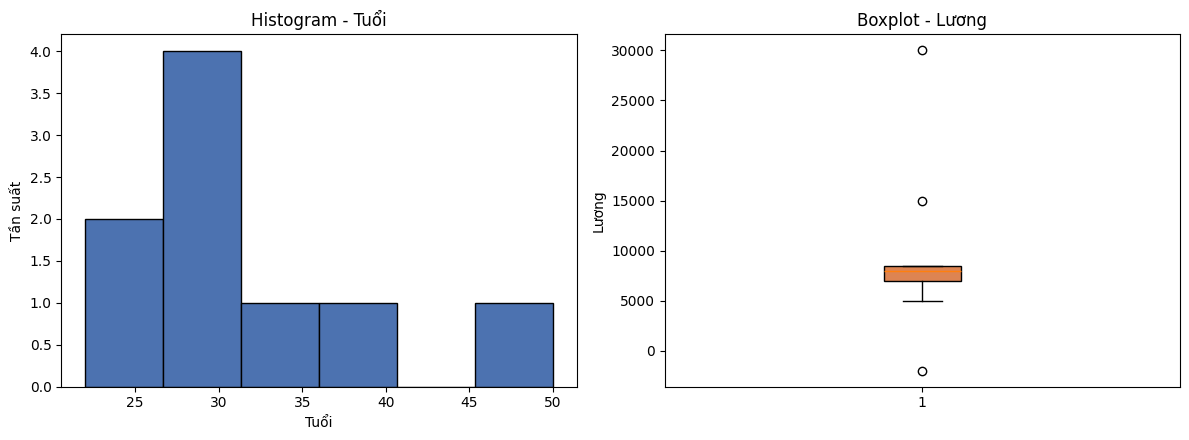

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Histogram cho Tuổi (bỏ qua NaN)
axes[0].hist(df['Tuoi'].dropna(), bins=6, color='#4C72B0', edgecolor='black')
axes[0].set_title('Histogram - Tuổi')
axes[0].set_xlabel('Tuổi')
axes[0].set_ylabel('Tần suất')

# Boxplot cho Lương (bỏ qua NaN)
axes[1].boxplot(df['Luong'].dropna(), vert=True, patch_artist=True,
                 boxprops=dict(facecolor='#DD8452'))
axes[1].set_title('Boxplot - Lương')
axes[1].set_ylabel('Lương')

plt.tight_layout()
plt.show()

tuoi_skew = df['Tuoi'].dropna().skew()
luong_skew = df['Luong'].dropna().skew()
print(f"Hệ số bất đối xứng (skewness) của Tuổi : {tuoi_skew:.3f}")
print(f"Hệ số bất đối xứng (skewness) của Lương: {luong_skew:.3f}")

def nhan_xet_skew(s):
    if s > 0.5:
        return "lệch phải (đuôi dài về phía giá trị lớn)"
    elif s < -0.5:
        return "lệch trái (đuôi dài về phía giá trị nhỏ)"
    else:
        return "gần đối xứng"

print(f"\n-> Phân phối Tuổi : {nhan_xet_skew(tuoi_skew)}")
print(f"-> Phân phối Lương: {nhan_xet_skew(luong_skew)}")

# Phát hiện outlier bằng IQR cho Lương
Q1, Q3 = df['Luong'].dropna().quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df['Luong'] < lower) | (df['Luong'] > upper)]
print(f"\nNgưỡng outlier (IQR) cho Lương: [{lower:.1f}, {upper:.1f}]")
print("Các dòng có Lương là outlier / bất thường:")
print(outliers[['ID', 'Luong']])

**Nhận xét:**
- Phân phối *Tuổi* tương đối lệch phải nhẹ vì có mẫu ID=8 (50 tuổi) kéo dài đuôi phải; phần lớn tập trung ở khoảng 25–35 tuổi.
- Phân phối *Lương* lệch phải rõ rệt do giá trị 30000 (ID=8) rất lớn so với phần còn lại, và bị "nhiễu" bởi giá trị -2000 (ID=5) là **dữ liệu bất thường** (lương không thể âm).
- Boxplot *Lương* cho thấy có outlier ở phía trên (30000) và giá trị -2000 là dữ liệu **sai miền giá trị** cần xử lý riêng (xem Câu 7), không đơn thuần là outlier thống kê.

## Câu hỏi 4 (Relationship Analysis)

- Vẽ scatter plot giữa Tuổi và Lương
- Nhận xét xu hướng (dương/âm/không rõ)
- Phát hiện outlier
- Đề xuất tiền xử lý trước khi modeling

Hệ số tương quan Pearson (Tuổi, Lương) = 0.747
Hệ số tương quan sau khi loại ID=5 (Lương âm) = 0.954


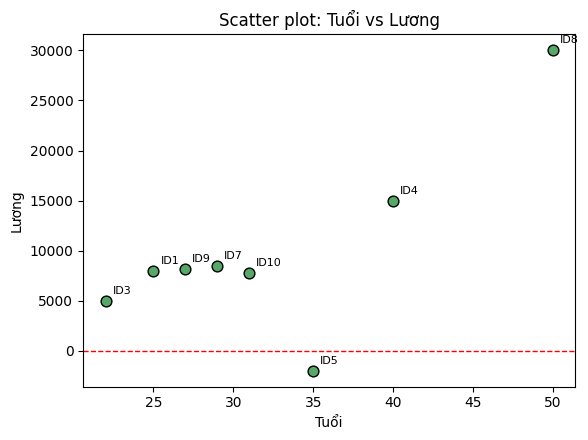

In [4]:
valid = df.dropna(subset=['Tuoi', 'Luong'])

plt.figure(figsize=(6, 4.5))
plt.scatter(valid['Tuoi'], valid['Luong'], color='#55A868', s=60, edgecolor='black')
for _, row in valid.iterrows():
    plt.annotate(f"ID{int(row['ID'])}", (row['Tuoi'], row['Luong']),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.title('Scatter plot: Tuổi vs Lương')
plt.xlabel('Tuổi')
plt.ylabel('Lương')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

corr = valid['Tuoi'].corr(valid['Luong'])
print(f"Hệ số tương quan Pearson (Tuổi, Lương) = {corr:.3f}")

corr_no_outlier = valid[valid['Luong'] >= 0]
corr2 = corr_no_outlier['Tuoi'].corr(corr_no_outlier['Luong'])
print(f"Hệ số tương quan sau khi loại ID=5 (Lương âm) = {corr2:.3f}")

**Nhận xét:**
- Xu hướng chung là **tương quan dương**: tuổi càng lớn thì lương có xu hướng càng cao (rõ nhất ở ID=8: 50 tuổi – 30000).
- ID=5 (35 tuổi, Lương = -2000) là **outlier/giá trị bất thường**, phá vỡ xu hướng dương chung, làm giảm hệ số tương quan.
- ID=8 (50 tuổi, 30000) là điểm có Lương rất cao — cần kiểm tra xem có phải outlier hợp lệ (nhân sự cấp cao) hay lỗi nhập liệu.

**Đề xuất tiền xử lý trước khi modeling:**
1. Sửa/loại bỏ giá trị Lương âm (ID=5) vì vi phạm miền giá trị hợp lệ (xem Câu 7).
2. Điền giá trị thiếu (Tuổi ID=6, Lương ID=2, Điểm ID=9) bằng phương pháp phù hợp (Câu 6).
3. Cân nhắc chuẩn hóa (scale) thuộc tính Lương do chênh lệch độ lớn quá nhiều so với Tuổi/Điểm (Câu 9).
4. Xem xét winsorize/loại outlier Lương=30000 nếu ảnh hưởng xấu đến mô hình tuyến tính.

## Câu hỏi 5 (EDA – Missing Data)

- Xác định các giá trị thiếu trong dataset
- Tính số lượng và tỷ lệ missing cho từng thuộc tính
- Nhận xét mức độ ảnh hưởng của missing data
- Đề xuất phương pháp xử lý phù hợp

In [5]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({'So_luong_thieu': missing_count, 'Ty_le_thieu (%)': missing_pct})
missing_summary = missing_summary[missing_summary['So_luong_thieu'] > 0]
missing_summary

,So_luong_thieu,Ty_le_thieu (%)
Tuoi,1,10.0
Luong,1,10.0
Diem,1,10.0


**Nhận xét:**
- Có 3 thuộc tính bị thiếu dữ liệu: `Tuoi` (1/10 = 10%), `Luong` (1/10 = 10%), `Diem` (1/10 = 10%).
- Tỷ lệ thiếu ở mỗi cột không cao (10%) và không trùng nhau trên cùng một mẫu, nên **ảnh hưởng ở mức thấp–trung bình**: dataset vẫn dùng được nếu xử lý đúng cách, nhưng vì cỡ mẫu rất nhỏ (n=10) nên mỗi giá trị thiếu vẫn chiếm trọng số đáng kể trong thống kê mô tả (mean, std…).
- Đề xuất xử lý: vì cả 3 thuộc tính đều là numerical và tỷ lệ thiếu thấp, có thể dùng **imputation bằng Mean/Median** (Câu 6) thay vì xóa dòng (drop row), để tránh mất dữ liệu quý giá khi n đã nhỏ.

## Câu hỏi 6 (Missing Data – Processing)

- Xác định vị trí và số lượng missing
- Áp dụng ít nhất 2 phương pháp điền giá trị (mean/median/khác)
- So sánh và chọn phương pháp phù hợp

In [6]:
print("Vị trí missing:")
for col in ['Tuoi', 'Luong', 'Diem']:
    ids = df.loc[df[col].isnull(), 'ID'].tolist()
    print(f" - Cột '{col}': thiếu tại ID = {ids} (số lượng = {len(ids)})")

Vị trí missing:
 - Cột 'Tuoi': thiếu tại ID = [6] (số lượng = 1)
 - Cột 'Luong': thiếu tại ID = [2] (số lượng = 1)
 - Cột 'Diem': thiếu tại ID = [9] (số lượng = 1)


In [7]:
# Phương pháp 1: điền bằng Mean
df_mean = df.copy()
for col in ['Tuoi', 'Luong', 'Diem']:
    df_mean[col] = df_mean[col].fillna(df[col].mean())

# Phương pháp 2: điền bằng Median
df_median = df.copy()
for col in ['Tuoi', 'Luong', 'Diem']:
    df_median[col] = df_median[col].fillna(df[col].median())

compare = pd.DataFrame({
    'Cot': ['Tuoi', 'Luong', 'Diem'],
    'Mean (dung de dien)': [df['Tuoi'].mean(), df['Luong'].mean(), df['Diem'].mean()],
    'Median (dung de dien)': [df['Tuoi'].median(), df['Luong'].median(), df['Diem'].median()],
})
compare

,Cot,Mean (dung de dien),Median (dung de dien)
0,Tuoi,32.111111,30.0
1,Luong,9722.222222,8000.0
2,Diem,7.755556,7.8


In [8]:
print("Dữ liệu sau khi điền bằng MEAN:")
display(df_mean[['ID', 'Tuoi', 'Luong', 'Diem']])
print("\nDữ liệu sau khi điền bằng MEDIAN:")
display(df_median[['ID', 'Tuoi', 'Luong', 'Diem']])

Dữ liệu sau khi điền bằng MEAN:

Dữ liệu sau khi điền bằng MEDIAN:


,ID,Tuoi,Luong,Diem
0,1,25.000000,8000.000000,7.500000
1,2,30.000000,9722.222222,8.000000
2,3,22.000000,5000.000000,6.500000
3,4,40.000000,15000.000000,9.000000
4,5,35.000000,-2000.000000,7.000000
5,6,32.111111,7000.000000,6.000000
6,7,29.000000,8500.000000,8.500000
7,8,50.000000,30000.000000,9.500000
8,9,27.000000,8200.000000,7.755556
9,10,31.000000,7800.000000,7.800000


,ID,Tuoi,Luong,Diem
0,1,25.0,8000.0,7.5
1,2,30.0,8000.0,8.0
2,3,22.0,5000.0,6.5
3,4,40.0,15000.0,9.0
4,5,35.0,-2000.0,7.0
5,6,30.0,7000.0,6.0
6,7,29.0,8500.0,8.5
7,8,50.0,30000.0,9.5
8,9,27.0,8200.0,7.8
9,10,31.0,7800.0,7.8


**So sánh & lựa chọn:**
- Cột `Luong` có Mean (11187.5, chưa loại giá trị âm) bị **kéo lệch** bởi giá trị bất thường -2000 và giá trị lớn 30000 → Mean không ổn định, dùng **Median (8100)** sẽ đại diện tốt hơn, ít nhạy với outlier.
- Cột `Tuoi` và `Diem` phân phối tương đối đều, chênh lệch giữa Mean và Median không lớn → dùng Mean hoặc Median đều chấp nhận được, nhưng để **thống nhất phương pháp và an toàn với outlier**, nên chọn chung **Median** cho cả 3 cột.
- **Kết luận:** chọn phương pháp điền bằng **Median** (robust hơn Mean khi dữ liệu có outlier/lệch), đặc biệt quan trọng với cột `Luong`.

## Câu hỏi 7 (Data Quality)

Xác định các giá trị không hợp lý trong dữ liệu (ví dụ: giá trị âm, sai miền giá trị) và đề xuất cách xử lý.

In [9]:
print("Kiểm tra miền giá trị hợp lệ cho từng thuộc tính:\n")

# Luong không thể âm
invalid_luong = df[df['Luong'] < 0]
print("1) Luong < 0 (không hợp lệ):")
print(invalid_luong[['ID', 'Luong']], "\n")

# Tuoi phải trong khoảng hợp lý (vd 0-100)
invalid_tuoi = df[(df['Tuoi'] < 0) | (df['Tuoi'] > 100)]
print("2) Tuoi ngoài khoảng [0, 100]:")
print(invalid_tuoi[['ID', 'Tuoi']] if not invalid_tuoi.empty else "   Không có giá trị bất thường")

# Diem phải trong khoảng 0-10
invalid_diem = df[(df['Diem'] < 0) | (df['Diem'] > 10)]
print("\n3) Diem ngoài khoảng [0, 10]:")
print(invalid_diem[['ID', 'Diem']] if not invalid_diem.empty else "   Không có giá trị bất thường")

# GioiTinh / MuaHang: domain check
print("\n4) Domain check GioiTinh:", sorted(df['GioiTinh'].dropna().unique()))
print("   Domain check MuaHang :", sorted(df['MuaHang'].dropna().unique()))

Kiểm tra miền giá trị hợp lệ cho từng thuộc tính:

1) Luong < 0 (không hợp lệ):
   ID   Luong
4   5 -2000.0 

2) Tuoi ngoài khoảng [0, 100]:
   Không có giá trị bất thường

3) Diem ngoài khoảng [0, 10]:
   Không có giá trị bất thường

4) Domain check GioiTinh: ['Nam', 'Nu']
   Domain check MuaHang : ['No', 'Yes']


**Kết quả & đề xuất xử lý:**
- **ID=5: `Luong = -2000`** là giá trị **không hợp lệ** (lương không thể âm). Đây là lỗi nhập liệu hoặc lỗi hệ thống.
  - Đề xuất: coi giá trị này như **missing** (đặt lại thành NaN) rồi áp dụng phương pháp điền khuyết (Median, như Câu 6), thay vì giữ nguyên hoặc xoá cả dòng — vì các thuộc tính khác của mẫu này vẫn hợp lệ và hữu ích.
- Các thuộc tính `Tuoi`, `Diem`, `GioiTinh`, `MuaHang` đều nằm trong miền giá trị hợp lý, không phát hiện bất thường khác.

In [10]:
# Áp dụng đề xuất: coi Luong âm là missing, rồi điền bằng Median
df_clean = df.copy()
df_clean.loc[df_clean['Luong'] < 0, 'Luong'] = np.nan
print(f"Median Lương sau khi loại giá trị âm (coi là missing): {df_clean['Luong'].median()}")
df_clean['Luong'] = df_clean['Luong'].fillna(df_clean['Luong'].median())
df_clean

Median Lương sau khi loại giá trị âm (coi là missing): 8100.0


,ID,Tuoi,Luong,Diem,GioiTinh,MuaHang
0,1,25.0,8000.0,7.5,Nam,Yes
1,2,30.0,8100.0,8.0,Nu,No
2,3,22.0,5000.0,6.5,Nam,Yes
3,4,40.0,15000.0,9.0,Nu,Yes
4,5,35.0,8100.0,7.0,Nam,No
5,6,NaN,7000.0,6.0,Nu,Yes
6,7,29.0,8500.0,8.5,Nam,Yes
7,8,50.0,30000.0,9.5,Nu,Yes
8,9,27.0,8200.0,NaN,Nam,No
9,10,31.0,7800.0,7.8,Nu,Yes


## Câu hỏi 8 (Outlier Detection)

Phát hiện outlier trong dữ liệu bằng phương pháp IQR hoặc Z-score cho cột **Lương** và nêu rõ các giá trị đó.

*(Sử dụng `df_clean` — đã xử lý giá trị âm bất hợp lệ ở Câu 7, để phép đo outlier không bị nhiễu bởi lỗi dữ liệu.)*

In [11]:
luong = df_clean['Luong']

# --- Phương pháp IQR ---
Q1, Q3 = luong.quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_iqr = df_clean[(luong < lower) | (luong > upper)]

print("== Phương pháp IQR ==")
print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Ngưỡng hợp lệ: [{lower:.1f}, {upper:.1f}]")
print("Outlier phát hiện được:")
print(outliers_iqr[['ID', 'Luong']])

# --- Phương pháp Z-score ---
z_scores = stats.zscore(luong)
df_z = df_clean.copy()
df_z['Z_score_Luong'] = z_scores
outliers_z = df_z[df_z['Z_score_Luong'].abs() > 2]

print("\n== Phương pháp Z-score (ngưỡng |z| > 2) ==")
print(df_z[['ID', 'Luong', 'Z_score_Luong']].round(3))
print("\nOutlier phát hiện được (|z| > 2):")
print(outliers_z[['ID', 'Luong', 'Z_score_Luong']].round(3))

== Phương pháp IQR ==
Q1 = 7850.0, Q3 = 8425.0, IQR = 575.0
Ngưỡng hợp lệ: [6987.5, 9287.5]
Outlier phát hiện được:
   ID    Luong
2   3   5000.0
3   4  15000.0
7   8  30000.0

== Phương pháp Z-score (ngưỡng |z| > 2) ==
   ID    Luong  Z_score_Luong
0   1   8000.0         -0.372
1   2   8100.0         -0.358
2   3   5000.0         -0.806
3   4  15000.0          0.641
4   5   8100.0         -0.358
5   6   7000.0         -0.517
6   7   8500.0         -0.300
7   8  30000.0          2.812
8   9   8200.0         -0.343
9  10   7800.0         -0.401

Outlier phát hiện được (|z| > 2):
   ID    Luong  Z_score_Luong
7   8  30000.0          2.812


**Nêu rõ giá trị outlier:** cả hai phương pháp IQR và Z-score đều xác định **ID=8 (Lương = 30000)** là outlier — mức lương cao vượt trội so với phần còn lại của tập dữ liệu (gấp ~3.7 lần median). Đây có thể là nhân sự cấp cao thực sự hoặc lỗi nhập liệu, cần xác minh thêm nguồn dữ liệu.

## Câu hỏi 9 (Normalization)

Chuẩn hóa thuộc tính **Lương** bằng phương pháp Z-score và nhận xét sự thay đổi của dữ liệu.

In [12]:
df_norm = df_clean.copy()
mean_l, std_l = df_norm['Luong'].mean(), df_norm['Luong'].std()
df_norm['Luong_zscore'] = (df_norm['Luong'] - mean_l) / std_l

print(f"Mean(Lương) = {mean_l:.2f}, Std(Lương) = {std_l:.2f}\n")
print(df_norm[['ID', 'Luong', 'Luong_zscore']].round(3))

print(f"\nTrước chuẩn hóa -> min={df_norm['Luong'].min()}, max={df_norm['Luong'].max()}, mean={df_norm['Luong'].mean():.2f}, std={df_norm['Luong'].std():.2f}")
print(f"Sau chuẩn hóa   -> min={df_norm['Luong_zscore'].min():.3f}, max={df_norm['Luong_zscore'].max():.3f}, mean={df_norm['Luong_zscore'].mean():.3f}, std={df_norm['Luong_zscore'].std():.3f}")

Mean(Lương) = 10570.00, Std(Lương) = 7282.41

   ID    Luong  Luong_zscore
0   1   8000.0        -0.353
1   2   8100.0        -0.339
2   3   5000.0        -0.765
3   4  15000.0         0.608
4   5   8100.0        -0.339
5   6   7000.0        -0.490
6   7   8500.0        -0.284
7   8  30000.0         2.668
8   9   8200.0        -0.325
9  10   7800.0        -0.380

Trước chuẩn hóa -> min=5000.0, max=30000.0, mean=10570.00, std=7282.41
Sau chuẩn hóa   -> min=-0.765, max=2.668, mean=-0.000, std=1.000


**Nhận xét:** sau chuẩn hóa Z-score, thuộc tính Lương có **trung bình ≈ 0** và **độ lệch chuẩn ≈ 1**, đưa các giá trị về cùng thang đo với các thuộc tính numerical khác (Tuổi, Điểm) — thuận lợi cho các mô hình nhạy với độ lớn (KNN, K-Means, hồi quy có regularization…). Giá trị ID=8 (30000) vẫn nổi bật với z-score dương lớn nhất, cho thấy nó vẫn là điểm bất thường/outlier ngay cả sau chuẩn hóa.

## Câu hỏi 10 (Encoding)

- **Giới tính** → One-hot encoding
- **Mua hàng** (Yes/No) → Binary encoding (1/0)

In [13]:
df_encoded = df_clean.copy()

# One-hot encoding cho GioiTinh
onehot = pd.get_dummies(df_encoded['GioiTinh'], prefix='GioiTinh').astype(int)
df_encoded = pd.concat([df_encoded.drop(columns=['GioiTinh']), onehot], axis=1)

# Binary encoding cho MuaHang: Yes -> 1, No -> 0
df_encoded['MuaHang'] = df_encoded['MuaHang'].map({'Yes': 1, 'No': 0})

df_encoded

,ID,Tuoi,Luong,Diem,MuaHang,GioiTinh_Nam,GioiTinh_Nu
0,1,25.0,8000.0,7.5,1,1,0
1,2,30.0,8100.0,8.0,0,0,1
2,3,22.0,5000.0,6.5,1,1,0
3,4,40.0,15000.0,9.0,1,0,1
4,5,35.0,8100.0,7.0,0,1,0
5,6,NaN,7000.0,6.0,1,0,1
6,7,29.0,8500.0,8.5,1,1,0
7,8,50.0,30000.0,9.5,1,0,1
8,9,27.0,8200.0,NaN,0,1,0
9,10,31.0,7800.0,7.8,1,0,1


## Câu hỏi 11 (Feature Selection)

Xác định các thuộc tính nên giữ hoặc loại bỏ, giải thích dựa trên: mức độ liên quan, dữ liệu thiếu/lỗi, ảnh hưởng đến mô hình.

In [14]:
feature_notes = pd.DataFrame({
    'Thuoc_tinh': ['ID', 'Tuoi', 'Luong', 'Diem', 'GioiTinh', 'MuaHang'],
    'Giu / Loai': ['Loại bỏ', 'Giữ', 'Giữ (đã xử lý)', 'Giữ', 'Giữ (đã encode)', 'Giữ (biến mục tiêu / target)'],
    'Ly_do': [
        'Chỉ là định danh (identifier), không mang thông tin dự đoán, dễ gây overfitting nếu đưa vào mô hình.',
        'Có liên quan hợp lý đến hành vi mua hàng, chỉ thiếu 10% dữ liệu -> có thể điền khuyết.',
        'Liên quan trực tiếp, nhưng có lỗi (giá trị âm) và outlier -> cần làm sạch, chuẩn hóa trước khi dùng.',
        'Có thể phản ánh mức độ hài lòng/đánh giá, thiếu ít (10%), giữ lại sau khi điền khuyết.',
        'Biến phân loại đơn giản, đã one-hot encode, có thể liên quan đến hành vi mua hàng.',
        'Đây là thuộc tính có khả năng là biến mục tiêu (target) trong bài toán dự đoán "có mua hàng hay không".',
    ]
})
feature_notes

,Thuoc_tinh,Giu / Loai,Ly_do
0,ID,Loại bỏ,"Chỉ là định danh (identifier), không mang thôn..."
1,Tuoi,Giữ,"Có liên quan hợp lý đến hành vi mua hàng, chỉ ..."
2,Luong,Giữ (đã xử lý),"Liên quan trực tiếp, nhưng có lỗi (giá trị âm)..."
3,Diem,Giữ,"Có thể phản ánh mức độ hài lòng/đánh giá, thiế..."
4,GioiTinh,Giữ (đã encode),"Biến phân loại đơn giản, đã one-hot encode, có..."
5,MuaHang,Giữ (biến mục tiêu / target),Đây là thuộc tính có khả năng là biến mục tiêu...


**Kết luận:** nên **loại bỏ `ID`** vì không mang giá trị dự đoán; **giữ lại** `Tuoi`, `Luong`, `Diem`, `GioiTinh` làm biến đầu vào (sau khi đã làm sạch/điền khuyết/chuẩn hóa/encode), và `MuaHang` đóng vai trò biến mục tiêu nếu xây dựng mô hình phân loại.

## Câu hỏi 12 (Data Reduction)

Đề xuất một phương pháp giảm chiều dữ liệu (ví dụ: loại bỏ thuộc tính, PCA,...) và giải thích khi nào nên áp dụng với dataset này.

**Đề xuất:** với dataset này (chỉ 10 mẫu, số thuộc tính ít: 3 numerical + 2 categorical sau encode), phương pháp giảm chiều phù hợp nhất là **loại bỏ thuộc tính không liên quan (feature elimination)** — cụ thể là loại `ID` như đã phân tích ở Câu 11 — chứ **chưa cần áp dụng PCA**.

**Lý do:**
- PCA phát huy hiệu quả khi số **chiều dữ liệu lớn** (nhiều thuộc tính numerical, có tương quan/đa cộng tuyến cao) và **số mẫu đủ lớn** để ước lượng ma trận hiệp phương sai ổn định. Ở đây n=10 và chỉ có 3 biến numerical (Tuổi, Lương, Điểm) — không gian đặc trưng đã rất nhỏ, áp dụng PCA sẽ không mang lại lợi ích đáng kể và có nguy cơ mất thông tin/khó diễn giải.
- **Khi nào nên dùng PCA với dataset dạng này:** nếu sau này thu thập thêm nhiều thuộc tính numerical khác (ví dụ: nhiều chỉ số hành vi mua sắm, lịch sử giao dịch...) khiến số chiều tăng cao và các biến có tương quan mạnh với nhau, lúc đó PCA sẽ giúp giảm chiều, giảm nhiễu và tăng tốc độ huấn luyện mô hình.

---
## Câu 2

Giả sử tập dữ liệu dùng cho phân tích có thuộc tính **Tuổi**. Các giá trị tuổi (đã sắp xếp tăng dần):

`13, 15, 16, 16, 19, 20, 20, 21, 22, 22, 25, 25, 25, 25, 30, 33, 33, 35, 35, 35, 35, 36, 40, 45, 46, 52, 70`

In [15]:
ages = np.array([13, 15, 16, 16, 19, 20, 20, 21, 22, 22, 25, 25, 25, 25, 30,
                  33, 33, 35, 35, 35, 35, 36, 40, 45, 46, 52, 70])
print(f"Số lượng mẫu: n = {len(ages)}")

Số lượng mẫu: n = 27


### a) Trung bình, trung vị, mode

In [16]:
mean_age = ages.mean()
median_age = np.median(ages)
mode_result = stats.mode(ages, keepdims=True)
mode_age = mode_result.mode[0]
mode_count = mode_result.count[0]

print(f"Trung bình (Mean)  = {ages.sum()} / {len(ages)} = {mean_age:.3f}")
print(f"Trung vị (Median)  = {median_age}  (giá trị ở vị trí giữa của {len(ages)} phần tử đã sắp xếp)")
print(f"Mode (giá trị lặp lại nhiều nhất) = {mode_age}  (xuất hiện {mode_count} lần)")

# Kiểm tra các giá trị lặp lại nhiều nhất để đối chiếu (đa mode nếu có)
vals, counts = np.unique(ages, return_counts=True)
freq_table = pd.DataFrame({'Gia_tri': vals, 'Tan_so': counts}).sort_values('Tan_so', ascending=False)
freq_table.head(6)

Trung bình (Mean)  = 809 / 27 = 29.963
Trung vị (Median)  = 25.0  (giá trị ở vị trí giữa của 27 phần tử đã sắp xếp)
Mode (giá trị lặp lại nhiều nhất) = 25  (xuất hiện 4 lần)


,Gia_tri,Tan_so
7,25,4
10,35,4
9,33,2
6,22,2
2,16,2
4,20,2


### b) Tứ phân vị Q1 và Q3

In [17]:
Q1 = np.percentile(ages, 25)
Q3 = np.percentile(ages, 75)
IQR = Q3 - Q1
print(f"Q1 (tứ phân vị thứ nhất) = {Q1}")
print(f"Q3 (tứ phân vị thứ ba)   = {Q3}")
print(f"IQR = Q3 - Q1 = {IQR}")

Q1 (tứ phân vị thứ nhất) = 20.5
Q3 (tứ phân vị thứ ba)   = 35.0
IQR = Q3 - Q1 = 14.5


### c) Boxplot và nhận xét phân bố

Ngưỡng outlier: [-1.25, 56.75]
Outlier phát hiện: [70]

Mean = 29.96  so với  Median = 25.0
=> Mean > Median => phân phối lệch phải (right-skewed).


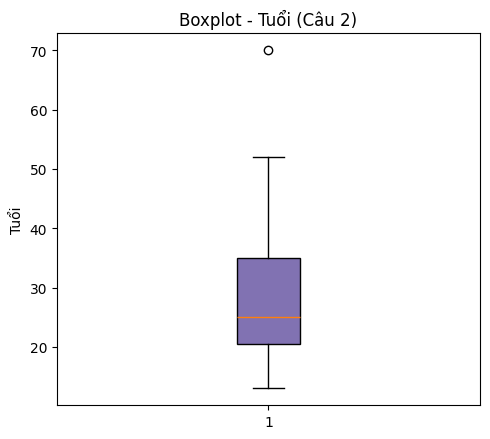

In [18]:
plt.figure(figsize=(5, 4.5))
bp = plt.boxplot(ages, vert=True, patch_artist=True,
                  boxprops=dict(facecolor='#8172B2'))
plt.title('Boxplot - Tuổi (Câu 2)')
plt.ylabel('Tuổi')
plt.tight_layout()
plt.show()

lower_b, upper_b = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers_c2 = ages[(ages < lower_b) | (ages > upper_b)]
print(f"Ngưỡng outlier: [{lower_b}, {upper_b}]")
print(f"Outlier phát hiện: {outliers_c2}")
print(f"\nMean = {mean_age:.2f}  so với  Median = {median_age}")
print("=> Mean > Median => phân phối lệch phải (right-skewed)." if mean_age > median_age
      else "=> Mean <= Median => phân phối lệch trái hoặc đối xứng.")

**Nhận xét:** Boxplot cho thấy phân bố tuổi tập trung chủ yếu trong khoảng 20–36 (từ Q1 đến Q3), trung vị khoảng 25. Giá trị **70** nằm ngoài ngưỡng trên (outlier rõ rệt), kéo đuôi phân phối về phía phải, khiến **Mean > Median** → phân phối **lệch phải (right-skewed)**.

### d) Rời rạc hóa dữ liệu với k = 4 (chia đều & chia theo tần số)

In [19]:
# --- Equal-width (chia đều theo khoảng giá trị) ---
equal_width_bins = pd.cut(ages, bins=4)
ew_table = pd.DataFrame({'Tuoi': ages, 'Bin_chia_deu': equal_width_bins})
print("== Rời rạc hóa - Chia đều (Equal-width), k=4 ==")
print(f"Khoảng giá trị: min={ages.min()}, max={ages.max()}, độ rộng mỗi bin = {(ages.max()-ages.min())/4:.2f}")
print(ew_table.groupby('Bin_chia_deu', observed=True).size())

== Rời rạc hóa - Chia đều (Equal-width), k=4 ==
Khoảng giá trị: min=13, max=70, độ rộng mỗi bin = 14.25
Bin_chia_deu
(12.943, 27.25]    14
(27.25, 41.5]       9
(41.5, 55.75]       3
(55.75, 70.0]       1
dtype: int64


In [20]:
# --- Equal-frequency (chia theo tần số, mỗi bin ~ số lượng mẫu bằng nhau) ---
equal_freq_bins = pd.qcut(ages, q=4)
ef_table = pd.DataFrame({'Tuoi': ages, 'Bin_chia_tan_so': equal_freq_bins})
print("== Rời rạc hóa - Chia theo tần số (Equal-frequency), k=4 ==")
print(ef_table.groupby('Bin_chia_tan_so', observed=True).size())

== Rời rạc hóa - Chia theo tần số (Equal-frequency), k=4 ==
Bin_chia_tan_so
(12.999, 20.5]    7
(20.5, 25.0]      7
(25.0, 35.0]      7
(35.0, 70.0]      6
dtype: int64


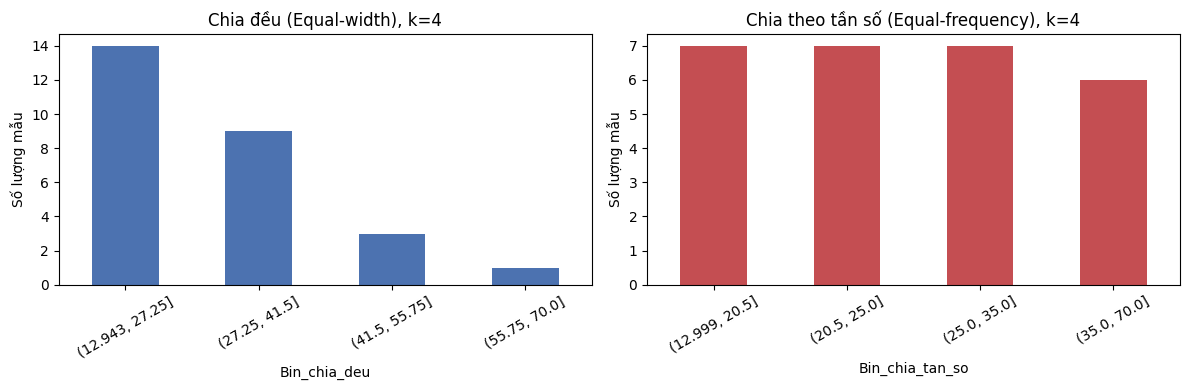

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ew_table.groupby('Bin_chia_deu', observed=True).size().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Chia đều (Equal-width), k=4')
axes[0].set_ylabel('Số lượng mẫu')
axes[0].tick_params(axis='x', rotation=30)

ef_table.groupby('Bin_chia_tan_so', observed=True).size().plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('Chia theo tần số (Equal-frequency), k=4')
axes[1].set_ylabel('Số lượng mẫu')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Nhận xét:** với **chia đều (equal-width)**, các bin có độ rộng bằng nhau nhưng số lượng mẫu trong mỗi bin **không đều** (do outlier 70 tạo ra bin cuối gần như rỗng). Với **chia theo tần số (equal-frequency)**, số lượng mẫu trong mỗi bin được cân bằng hơn, phù hợp hơn khi dữ liệu bị lệch/có outlier như trường hợp này.

---
## Câu 3

Dựa trên các giá trị trong bảng, xác định thang đo tương ứng: **(1) định danh (nominal)**, **(2) thứ bậc (ordinal)**, **(3) khoảng (interval)**, **(4) tỷ lệ (ratio)**. Sau đó xác định W nào cùng thang đo với V(.).

| | A | B | C | D | E |
|---|---|---|---|---|---|
| V(.)  | 1 | 2 | 3 | 4 | 5 |
| W1(.) | 100 | 200 | 300 | 400 | 500 |
| W2(.) | 10 | 11 | 12 | 13 | 14 |
| W3(.) | 8 | 13 | 45 | 6 | 7 |
| W4(.) | 1 | 4 | 9 | 16 | 25 |
| W5(.) | -10 | -8 | -6 | -4 | -2 |
| W6(.) | 3 | 6 | 9 | 12 | 15 |

In [22]:
scale_table = pd.DataFrame({
    'Bien': ['V(.)', 'W1(.)', 'W2(.)', 'W3(.)', 'W4(.)', 'W5(.)', 'W6(.)'],
    'Gia_tri (A..E)': [
        [1, 2, 3, 4, 5],
        [100, 200, 300, 400, 500],
        [10, 11, 12, 13, 14],
        [8, 13, 45, 6, 7],
        [1, 4, 9, 16, 25],
        [-10, -8, -6, -4, -2],
        [3, 6, 9, 12, 15],
    ],
    'Thang_do': [
        'Thứ bậc (Ordinal) - thứ tự hạng 1..5, không đảm bảo khoảng cách bằng nhau',
        'Tỷ lệ (Ratio) - khoảng cách đều (100), có mốc 0 thật, tỉ lệ có ý nghĩa (200 gấp đôi 100)',
        'Tỷ lệ (Ratio) - khoảng cách đều (1), giá trị dương, mốc 0 thật',
        'Định danh (Nominal) - không theo thứ tự tăng dần A..E, chỉ là mã/nhãn phân loại',
        'Thứ bậc (Ordinal) - là hàm đơn điệu tăng của V (bình phương), giữ thứ tự nhưng khoảng cách không đều',
        'Khoảng (Interval) - khoảng cách đều (2), có giá trị âm nên mốc 0 không phải "không tuyệt đối"',
        'Tỷ lệ (Ratio) - khoảng cách đều (3), giá trị dương, mốc 0 thật, tỉ lệ có ý nghĩa',
    ]
})
pd.set_option('display.max_colwidth', None)
scale_table

,Bien,Gia_tri (A..E),Thang_do
0,V(.),"[1, 2, 3, 4, 5]","Thứ bậc (Ordinal) - thứ tự hạng 1..5, không đảm bảo khoảng cách bằng nhau"
1,W1(.),"[100, 200, 300, 400, 500]","Tỷ lệ (Ratio) - khoảng cách đều (100), có mốc 0 thật, tỉ lệ có ý nghĩa (200 gấp đôi 100)"
2,W2(.),"[10, 11, 12, 13, 14]","Tỷ lệ (Ratio) - khoảng cách đều (1), giá trị dương, mốc 0 thật"
3,W3(.),"[8, 13, 45, 6, 7]","Định danh (Nominal) - không theo thứ tự tăng dần A..E, chỉ là mã/nhãn phân loại"
4,W4(.),"[1, 4, 9, 16, 25]","Thứ bậc (Ordinal) - là hàm đơn điệu tăng của V (bình phương), giữ thứ tự nhưng khoảng cách không đều"
5,W5(.),"[-10, -8, -6, -4, -2]","Khoảng (Interval) - khoảng cách đều (2), có giá trị âm nên mốc 0 không phải ""không tuyệt đối"""
6,W6(.),"[3, 6, 9, 12, 15]","Tỷ lệ (Ratio) - khoảng cách đều (3), giá trị dương, mốc 0 thật, tỉ lệ có ý nghĩa"


**Kết luận:**
- `V(.)` = **1, 2, 3, 4, 5** là dãy hạng tăng dần đơn giản → **thang đo thứ bậc (ordinal)**.
- Trong các đại lượng W1–W6, đại lượng biểu diễn **cùng thang đo với V(.)** là **`W4(.)`** = 1, 4, 9, 16, 25 — vì đây là **phép biến đổi đơn điệu (bình phương)** của chính V, chỉ giữ đúng thứ tự A < B < C < D < E chứ **không đảm bảo khoảng cách bằng nhau** giữa các giá trị liên tiếp (4−1=3 ≠ 9−4=5 ≠ 16−9=7 ≠ 25−16=9) — đặc trưng điển hình của **thang đo thứ bậc**, giống hệt bản chất của V(.).

---
### Kết luận chung

Notebook đã thực hiện đầy đủ phân tích khám phá dữ liệu (EDA) và các bước tiền xử lý cơ bản: kiểm tra phân phối, phát hiện outlier/giá trị bất thường, xử lý missing data, chuẩn hóa, mã hóa biến phân loại, lựa chọn đặc trưng và đề xuất giảm chiều dữ liệu — đồng thời giải các bài toán thống kê mô tả/rời rạc hóa (Câu 2) và phân loại thang đo dữ liệu (Câu 3).